# Part-3: Classical Statistical Models (AR, MA, ARMA, ARIMA, SARIMA)

**Time Series in Machine Learning** — Daneshkar.net

---


In [ ]:
# Install required packages (uncomment if needed)
# %pip install numpy
# %pip install pandas
# %pip install matplotlib
# %pip install statsmodels
# %pip install scipy
# %pip install scikit-learn
# %pip install pmdarima

# Or install all at once:
# %pip install numpy pandas matplotlib statsmodels scipy scikit-learn pmdarima


In [1]:
# Common imports & Jupyter setup
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
print("Setup complete! Ready to run.")


Setup complete! Ready to run.


---
## Autoregressive Models
*Source: 01_autoregressive_models.py*


In [5]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
from statsmodels.tsa.stattools import pacf
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ---------- Setup ----------
OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)
n_obs = 200


## 1. Manual AR(1) Generation


SECTION 1: Manual AR(1) Generation
  Generated AR(1) with phi=0.8, constant=1.0
  Long-run mean = 5.00



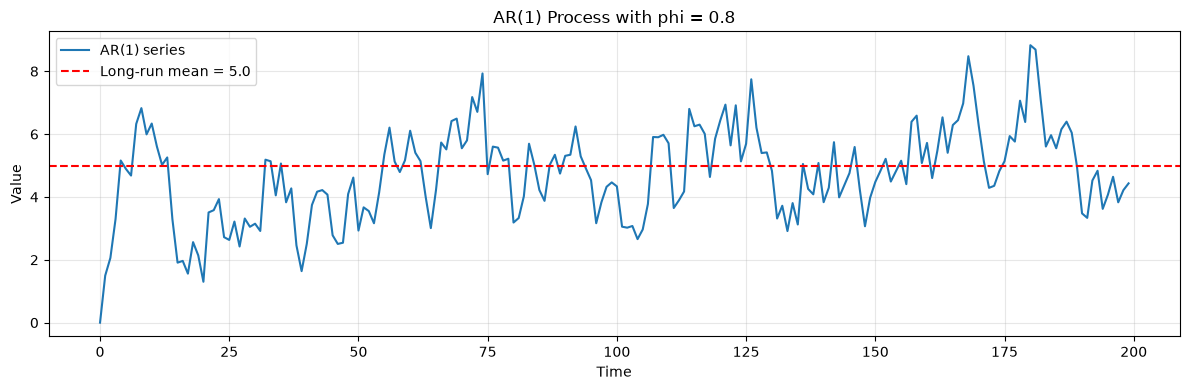

In [11]:
print("=" * 60)
print("SECTION 1: Manual AR(1) Generation")
print("=" * 60)
np.random.seed(42)

phi = 0.8
c = 1.0
y = [0]

for t in range(1, n_obs):
    noise = np.random.normal(0, 1)
    y.append(c + phi * y[-1] + noise)

ar1_series = pd.Series(y, name='AR(1)')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ar1_series, label='AR(1) series')
ax.axhline(y=c / (1 - phi), color='r', linestyle='--',
           label=f'Long-run mean = {c / (1 - phi):.1f}')
ax.set_title(f'AR(1) Process with phi = {phi}')
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '01_ar1_generation.png'), dpi=100)
print(f"  Generated AR(1) with phi={phi}, constant={c}")
print(f"  Long-run mean = {c/(1-phi):.2f}\n")


## 2. Compare AR(1) with Different phi Values


SECTION 2: Comparing AR(1) with Different phi Values
  Saved comparison plot for phi = [0, 0.3, 0.7, 0.95] 



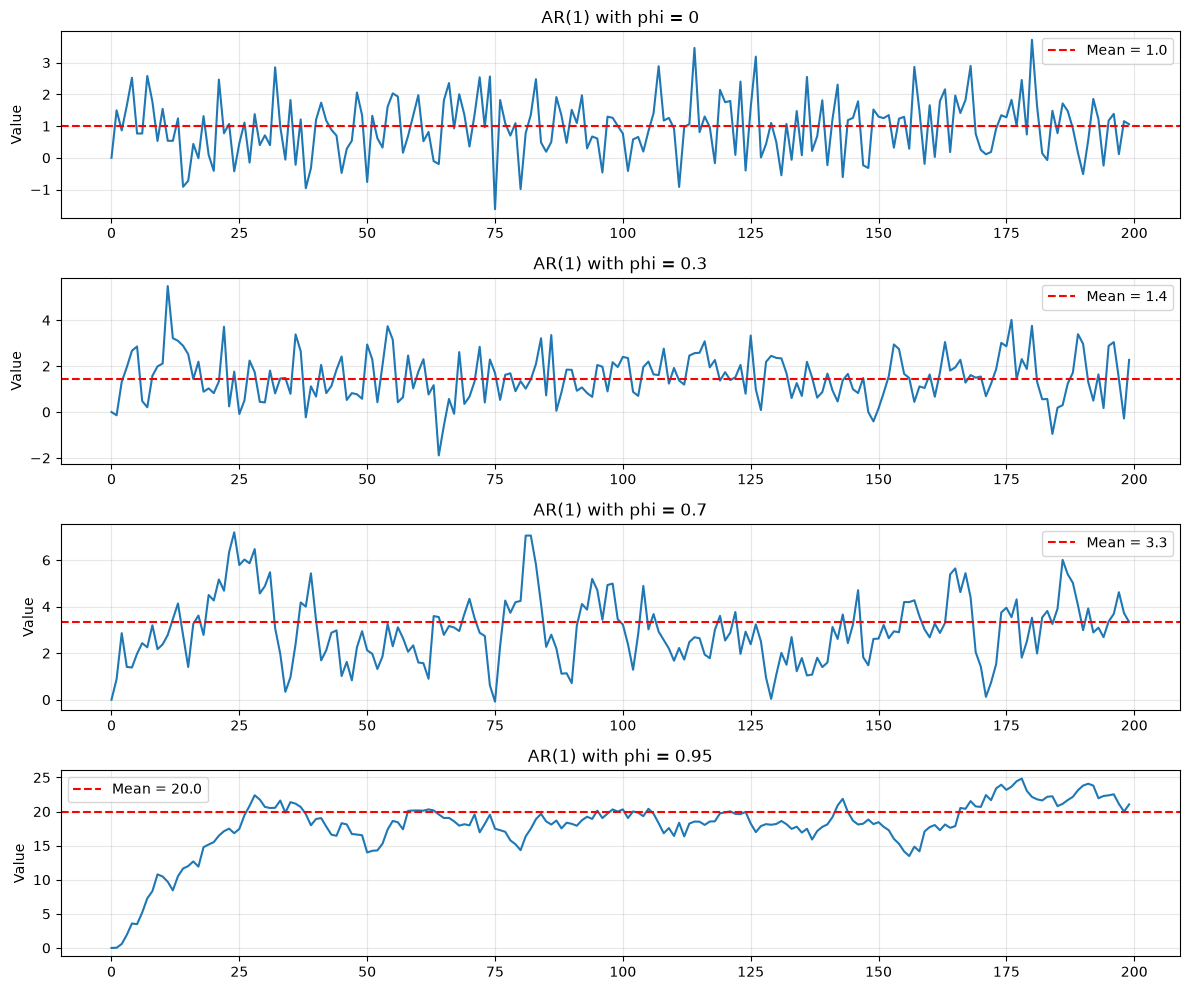

In [16]:
print("=" * 60)
print("SECTION 2: Comparing AR(1) with Different phi Values")
print("=" * 60)
np.random.seed(42)

phi_values = [0, 0.3, 0.7, 0.95]
fig, axes = plt.subplots(len(phi_values), 1, figsize=(12, 10))

for ax, phi_val in zip(axes, phi_values):
    y_sim = [0]
    for t in range(1, n_obs):
        y_sim.append(c + phi_val * y_sim[-1] + np.random.normal(0, 1))
    ax.plot(y_sim)
    ax.set_title(f'AR(1) with phi = {phi_val}')
    ax.set_ylabel('Value')
    ax.grid(True, alpha=0.3)
    # Show long-run mean if stationary
    if abs(phi_val) < 1:
        ax.axhline(y=c / (1 - phi_val), color='r', linestyle='--',
                   label=f'Mean = {c/(1-phi_val):.1f}')
        ax.legend()
    else:
        ax.text(0.95, 0.95, 'Non-stationary', transform=ax.transAxes,
                ha='right', va='top', fontsize=11, color='red')

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '02_ar1_phi_comparison.png'), dpi=100)
print("  Saved comparison plot for phi =", phi_values, "\n")


## 3. Fit AR with statsmodels AutoReg


In [17]:
print("=" * 60)
print("SECTION 3: Fitting AR Model with AutoReg")
print("=" * 60)

p_lags = 2
model_ar = AutoReg(ar1_series, lags=p_lags)
result_ar = model_ar.fit()
print(f"  AutoReg(2) fitted successfully")
print(f"  AIC: {result_ar.aic:.2f}")
print(f"  BIC: {result_ar.bic:.2f}")
print(f"  Coefficients: {result_ar.params.to_dict()}\n")


SECTION 3: Fitting AR Model with AutoReg
  AutoReg(2) fitted successfully
  AIC: 539.49
  BIC: 552.64
  Coefficients: {'const': 1.2114697360239788, 'AR(1).L1': 0.7428377322498222, 'AR(1).L2': 0.0045277621476116844}



## 4. PACF Analysis to Determine p


SECTION 4: PACF Analysis to Determine p
  Estimated p from PACF: 5



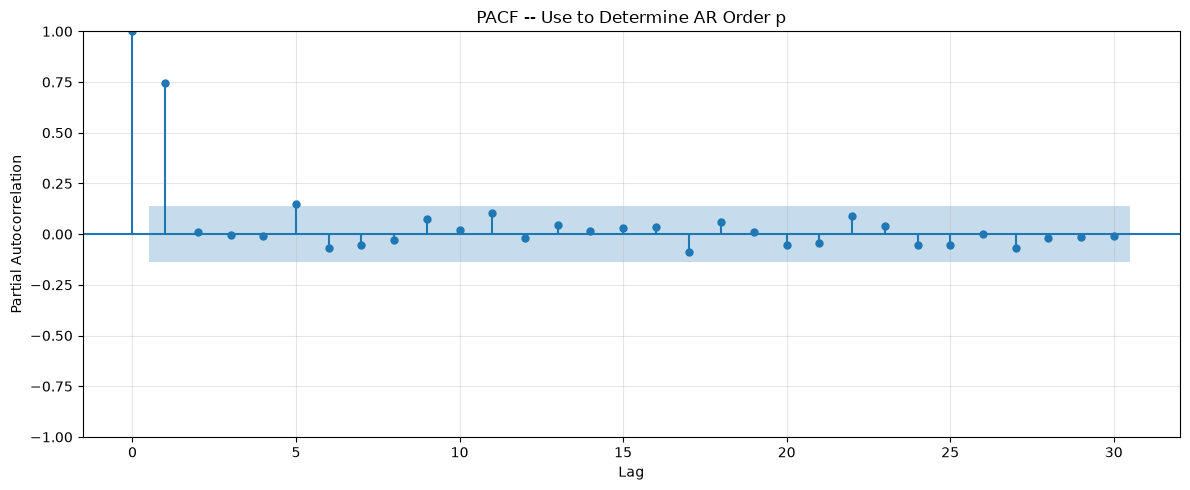

In [19]:
print("=" * 60)
print("SECTION 4: PACF Analysis to Determine p")
print("=" * 60)

fig, ax = plt.subplots(figsize=(12, 5))
plot_pacf(ar1_series.dropna(), lags=30, ax=ax)
ax.set_title('PACF -- Use to Determine AR Order p')
ax.set_xlabel('Lag')
ax.set_ylabel('Partial Autocorrelation')
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '03_pacf_ar_order.png'), dpi=100)
# Automatic detection from PACF
pacf_vals, pacf_confint = pacf(ar1_series.dropna(), nlags=30, alpha=0.05)
conf_width = pacf_confint[:, 1] - pacf_vals
significant = np.where(np.abs(pacf_vals) > conf_width)[0]
p_estimated = significant[-1] if len(significant) > 0 else 1
print(f"  Estimated p from PACF: {p_estimated}\n")


## 5. Grid Search for Best p Using AIC


SECTION 5: Grid Search for Best p Using AIC
  Best p by AIC: 1 (AIC = 552.53)
 p        AIC        BIC
 1 552.531672 562.426625
 2 554.527715 567.720984
 3 556.527004 573.018591
 4 558.435840 578.225744
 5 556.831061 579.919283
 6 557.627800 584.014338
 7 559.017765 588.702621
 8 560.144345 593.127519
 9 561.386839 597.668330
10 563.185249 602.765057
11 563.057562 605.935688
12 564.826348 611.002791
13 566.231044 615.705805
14 568.188008 620.961086
15 569.325785 625.397180
16 570.346756 629.716469
17 570.695256 633.363286
18 571.466247 637.432594
19 573.428752 642.693416
20 575.081572 647.644554


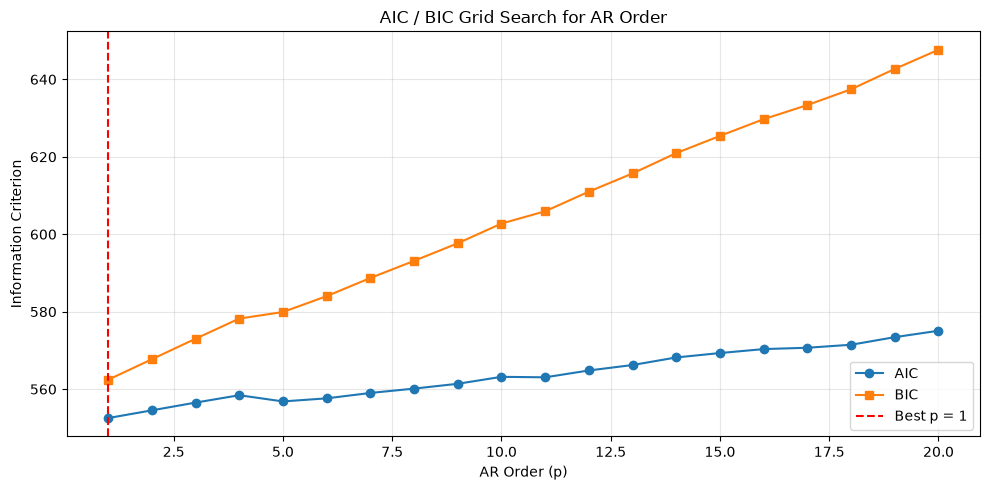

In [20]:
print("=" * 60)
print("SECTION 5: Grid Search for Best p Using AIC")
print("=" * 60)

best_aic = np.inf
best_p = 0
results = []

for p in range(1, 21):
    try:
        model = ARIMA(ar1_series, order=(p, 0, 0))
        fitted = model.fit()
        results.append({'p': p, 'AIC': fitted.aic, 'BIC': fitted.bic})
        if fitted.aic < best_aic:
            best_aic = fitted.aic
            best_p = p
    except Exception:
        continue

results_df = pd.DataFrame(results)
print(f"  Best p by AIC: {best_p} (AIC = {best_aic:.2f})")
print(results_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(results_df['p'], results_df['AIC'], 'o-', label='AIC')
ax.plot(results_df['p'], results_df['BIC'], 's-', label='BIC')
ax.axvline(x=best_p, color='r', linestyle='--', label=f'Best p = {best_p}')
ax.set_xlabel('AR Order (p)')
ax.set_ylabel('Information Criterion')
ax.set_title('AIC / BIC Grid Search for AR Order')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '04_ar_grid_search.png'), dpi=100)


## 6. Forecasting with AR Model


SECTION 6: Forecasting with AR Model
  Model AR(1) -- AIC: 462.62, BIC: 472.01
  Forecast performance: MSE=2.1947, RMSE=1.4815, MAE=1.1494

All plots saved successfully.
Done -- 01_autoregressive_models.py


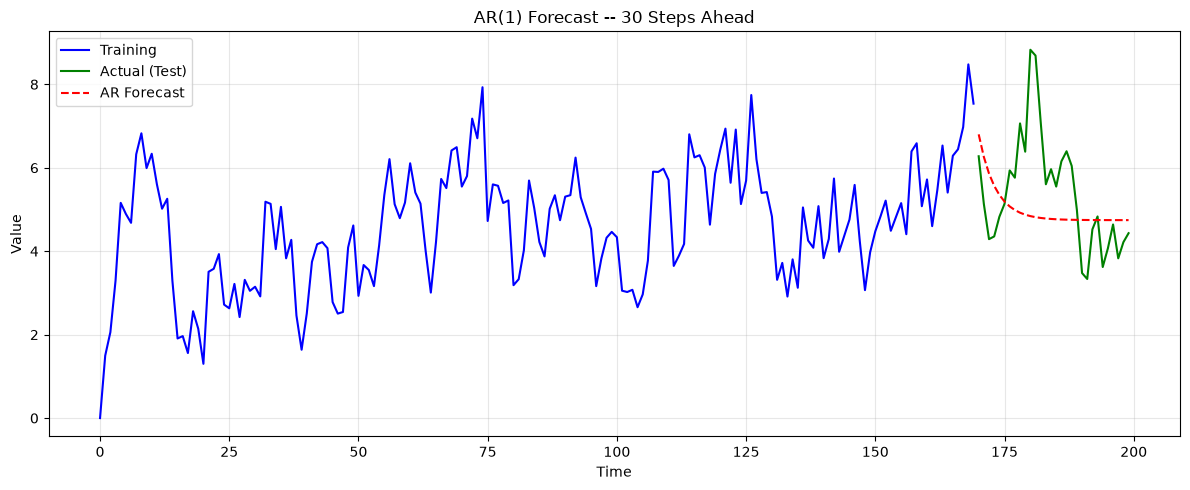

In [24]:
print("=" * 60)
print("SECTION 6: Forecasting with AR Model")
print("=" * 60)

def fit_and_forecast_ar(series, p=None, test_size=20):
    """Fit AR(p) on training data and forecast the test period."""
    train = series[:-test_size]
    test = series[-test_size:]

    if p is None:
        pacf_vals, pacf_ci = pacf(train.dropna(), nlags=min(30, len(train)//3), alpha=0.05)
        conf_w = pacf_ci[:, 1] - pacf_vals
        sig = np.where(np.abs(pacf_vals) > conf_w)[0]
        p = sig[-1] if len(sig) > 0 else 1
        print(f"  Auto-selected p = {p}")

    model = AutoReg(train, lags=p)
    fitted = model.fit()
    print(f"  Model AR({p}) -- AIC: {fitted.aic:.2f}, BIC: {fitted.bic:.2f}")

    forecasts = fitted.predict(start=len(train), end=len(train) + len(test) - 1)
    forecasts = pd.Series(forecasts, index=test.index)

    mse = mean_squared_error(test, forecasts)
    mae = mean_absolute_error(test, forecasts)
    rmse = np.sqrt(mse)
    print(f"  Forecast performance: MSE={mse:.4f}, RMSE={rmse:.4f}, MAE={mae:.4f}")

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(train.index, train, label='Training', color='blue')
    ax.plot(test.index, test, label='Actual (Test)', color='green')
    ax.plot(test.index, forecasts, label='AR Forecast', color='red', linestyle='--')
    ax.set_title(f'AR({p}) Forecast -- {test_size} Steps Ahead')
    ax.set_xlabel('Time')
    ax.set_ylabel('Value')
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, '05_ar_forecast.png'), dpi=100)
    return fitted, forecasts

fitted_ar, preds_ar = fit_and_forecast_ar(ar1_series, p=best_p, test_size=30)

print("\nAll plots saved successfully.")
print("Done -- 01_autoregressive_models.py")


---
## Moving Average Models


In [25]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ---------- Setup ----------
OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)
n_obs = 300


## 1. Manual MA(1) Generation


SECTION 1: Manual MA(1) Generation
  Generated MA(1) with mu=0.0, theta1=0.7



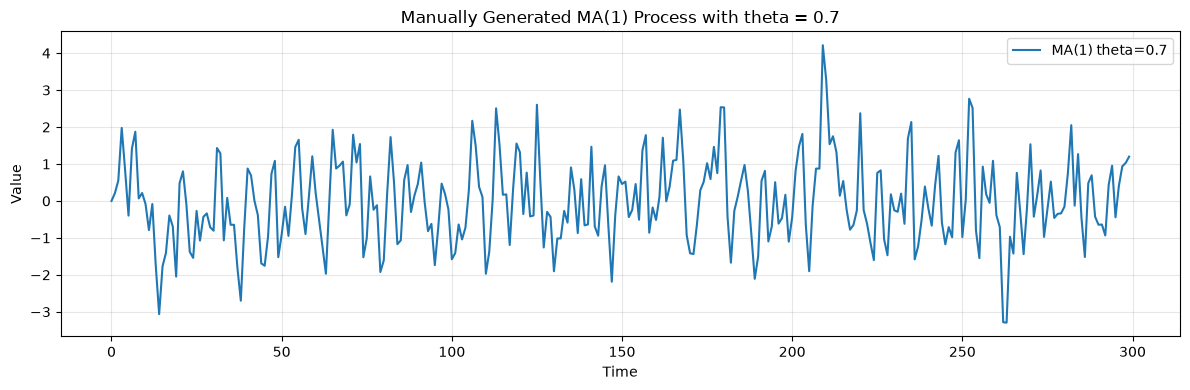

In [27]:
print("=" * 60)
print("SECTION 1: Manual MA(1) Generation")
print("=" * 60)
np.random.seed(42)

mu = 0.0
theta1 = 0.7

epsilon = np.random.normal(0, 1, n_obs)
y_ma1 = np.zeros(n_obs)
for t in range(1, n_obs):
    y_ma1[t] = mu + epsilon[t] + theta1 * epsilon[t - 1]

ma1_series = pd.Series(y_ma1, name='MA(1)')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ma1_series, label=f'MA(1) theta={theta1}')
ax.set_title(f'Manually Generated MA(1) Process with theta = {theta1}')
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '01_ma1_manual.png'), dpi=100)
print(f"  Generated MA(1) with mu={mu}, theta1={theta1}\n")


## 2. Generate MA Process with arma_generate_sample


SECTION 2: MA Process via arma_generate_sample
  Generated MA(2) with ArmaProcess



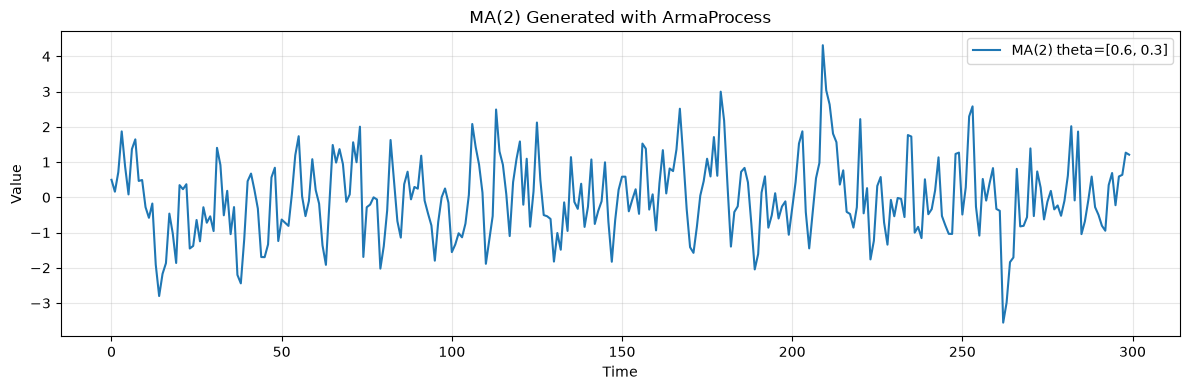

In [28]:
print("=" * 60)
print("SECTION 2: MA Process via arma_generate_sample")
print("=" * 60)
np.random.seed(42)

# MA(2): Y_t = eps_t + 0.6*eps_{t-1} + 0.3*eps_{t-2}
ma_params = np.array([1, 0.6, 0.3])   # [1, theta1, theta2]
ar_params = np.array([1])             # pure MA

arma_proc = ArmaProcess(ar_params, ma_params)
ma2_sample = arma_proc.generate_sample(nsample=n_obs)
ma2_series = pd.Series(ma2_sample, name='MA(2)')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ma2_series, label='MA(2) theta=[0.6, 0.3]')
ax.set_title('MA(2) Generated with ArmaProcess')
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '02_ma2_sample.png'), dpi=100)
print("  Generated MA(2) with ArmaProcess\n")


## 3. ACF Analysis to Determine q


SECTION 3: ACF Analysis to Determine q
  Estimated q from ACF: 20



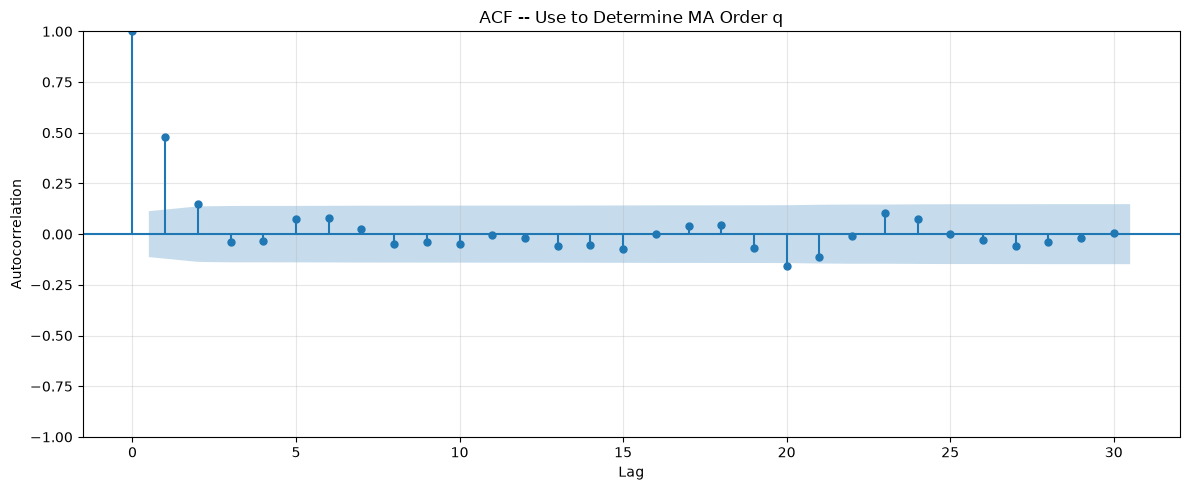

In [29]:
print("=" * 60)
print("SECTION 3: ACF Analysis to Determine q")
print("=" * 60)

fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(ma2_series.dropna(), lags=30, ax=ax)
ax.set_title('ACF -- Use to Determine MA Order q')
ax.set_xlabel('Lag')
ax.set_ylabel('Autocorrelation')
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '03_acf_ma_order.png'), dpi=100)
# Automatic detection from ACF
acf_vals, acf_confint = acf(ma2_series.dropna(), nlags=30, alpha=0.05)
conf_width = acf_confint[:, 1] - acf_vals
significant = np.where(np.abs(acf_vals[1:]) > conf_width[1:])[0]
q_estimated = significant[-1] + 1 if len(significant) > 0 else 0
print(f"  Estimated q from ACF: {q_estimated}\n")


## 4. Grid Search for Best q Using AIC


SECTION 4: Grid Search for Best q Using AIC
  Best q by AIC: 2 (AIC = 846.15)
 q        AIC        BIC
 1 858.184988 869.296335
 2 846.147124 860.962254
 3 847.830236 866.349148
 4 846.951652 869.174346
 5 848.946578 874.873055
 6 850.414992 880.045252
 7 850.935014 884.269056
 8 852.840064 889.877889
 9 854.813113 895.554721
10 855.708525 900.153914
11 857.700734 905.849906
12 859.698030 911.550985
13 860.470890 916.027627
14 862.350215 921.610734
15 863.416935 926.381237
16 865.381101 932.049186
17 866.807853 937.179720
18 868.499416 942.575065
19 869.500070 947.279502
20 870.925853 952.409067


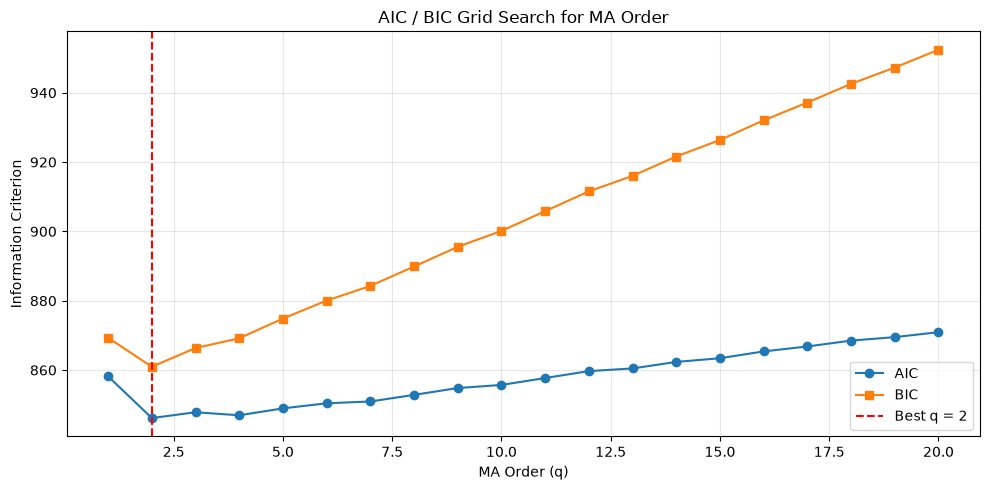

In [30]:
print("=" * 60)
print("SECTION 4: Grid Search for Best q Using AIC")
print("=" * 60)

best_aic = np.inf
best_q = 0
results = []

for q in range(1, 21):
    try:
        model = ARIMA(ma2_series, order=(0, 0, q))
        fitted = model.fit()
        results.append({'q': q, 'AIC': fitted.aic, 'BIC': fitted.bic})
        if fitted.aic < best_aic:
            best_aic = fitted.aic
            best_q = q
    except Exception:
        continue

results_df = pd.DataFrame(results)
print(f"  Best q by AIC: {best_q} (AIC = {best_aic:.2f})")
print(results_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(results_df['q'], results_df['AIC'], 'o-', label='AIC')
ax.plot(results_df['q'], results_df['BIC'], 's-', label='BIC')
ax.axvline(x=best_q, color='r', linestyle='--', label=f'Best q = {best_q}')
ax.set_xlabel('MA Order (q)')
ax.set_ylabel('Information Criterion')
ax.set_title('AIC / BIC Grid Search for MA Order')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '04_ma_grid_search.png'), dpi=100)


## 5. Fit and Forecast with MA Model


SECTION 5: Fit and Forecast with MA Model
  Model MA(2) -- AIC: 767.71, BIC: 782.10
  Coefficients: {'const': -0.032868277362742, 'ma.L1': 0.5466230417143632, 'ma.L2': 0.2363093921835987, 'sigma2': 0.9749422614046648}
  Forecast performance: MSE=0.6849, RMSE=0.8276, MAE=0.6522

  Model MA(1) -- AIC: 766.75, BIC: 777.54
  Coefficients: {'const': -0.033502310835775526, 'ma.L1': 0.7486158467043005, 'sigma2': 0.9769196237200624}
  Forecast performance: MSE=0.7168, RMSE=0.8467, MAE=0.7101

All plots saved successfully.
Done -- 02_moving_average_models.py


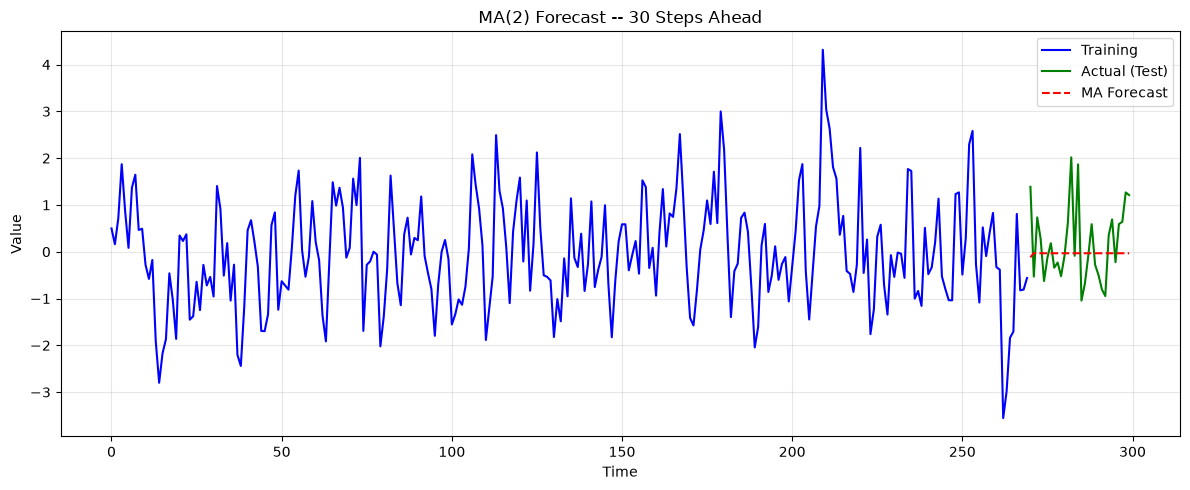

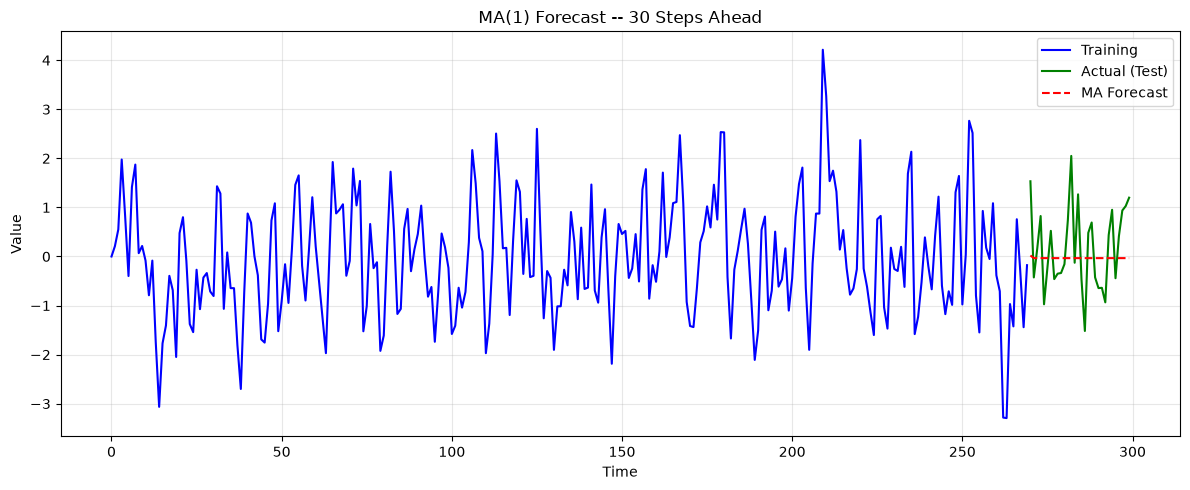

In [31]:
print("=" * 60)
print("SECTION 5: Fit and Forecast with MA Model")
print("=" * 60)

def fit_and_forecast_ma(series, q=None, test_size=20):
    """Fit MA(q) on training data and forecast the test period."""
    train = series[:-test_size]
    test = series[-test_size:]

    if q is None:
        acf_vals, acf_ci = acf(train.dropna(), nlags=min(30, len(train)//3), alpha=0.05)
        conf_w = acf_ci[:, 1] - acf_vals
        sig = np.where(np.abs(acf_vals[1:]) > conf_w[1:])[0]
        q = sig[-1] + 1 if len(sig) > 0 else 1
        print(f"  Auto-selected q = {q}")

    model = ARIMA(train, order=(0, 0, q))
    fitted = model.fit()
    print(f"  Model MA({q}) -- AIC: {fitted.aic:.2f}, BIC: {fitted.bic:.2f}")
    print(f"  Coefficients: {fitted.params.to_dict()}")

    forecasts = fitted.forecast(steps=len(test))
    forecasts = pd.Series(forecasts, index=test.index)

    mse = mean_squared_error(test, forecasts)
    mae = mean_absolute_error(test, forecasts)
    rmse = np.sqrt(mse)
    print(f"  Forecast performance: MSE={mse:.4f}, RMSE={rmse:.4f}, MAE={mae:.4f}")

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(train.index, train, label='Training', color='blue')
    ax.plot(test.index, test, label='Actual (Test)', color='green')
    ax.plot(test.index, forecasts, label='MA Forecast', color='red', linestyle='--')
    ax.set_title(f'MA({q}) Forecast -- {test_size} Steps Ahead')
    ax.set_xlabel('Time')
    ax.set_ylabel('Value')
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, '05_ma_forecast.png'), dpi=100)
    return fitted, forecasts

fitted_ma, preds_ma = fit_and_forecast_ma(ma2_series, q=best_q, test_size=30)

# Also fit on the MA(1) series
print()
fit_and_forecast_ma(ma1_series, q=1, test_size=30)

print("\nAll plots saved successfully.")
print("Done -- 02_moving_average_models.py")


---
## Arma Models


In [32]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats as scipy_stats
from sklearn.metrics import mean_squared_error

# ---------- Setup ----------
OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)
n_obs = 500


## 1. Generate ARMA(1,1) with statsmodels


In [33]:
print("=" * 60)
print("SECTION 1: Generate ARMA(1,1) Process")
print("=" * 60)
np.random.seed(42)

# ARMA(1,1): phi1 = 0.7, theta1 = -0.4
ar_params = np.array([1, -0.7])   # [1, -phi1]
ma_params = np.array([1, -0.4])   # [1, theta1]

arma_process = ArmaProcess(ar_params, ma_params)
arma_series = arma_process.generate_sample(nsample=n_obs)
arma_series = pd.Series(arma_series, name='ARMA(1,1)')

print(f"  Generated ARMA(1,1) with phi1=0.7, theta1=-0.4")
print(f"  Length: {n_obs}\n")


SECTION 1: Generate ARMA(1,1) Process
  Generated ARMA(1,1) with phi1=0.7, theta1=-0.4
  Length: 500



## 2. ACF / PACF Analysis


SECTION 2: ACF and PACF Analysis
  Saved ACF/PACF analysis plot



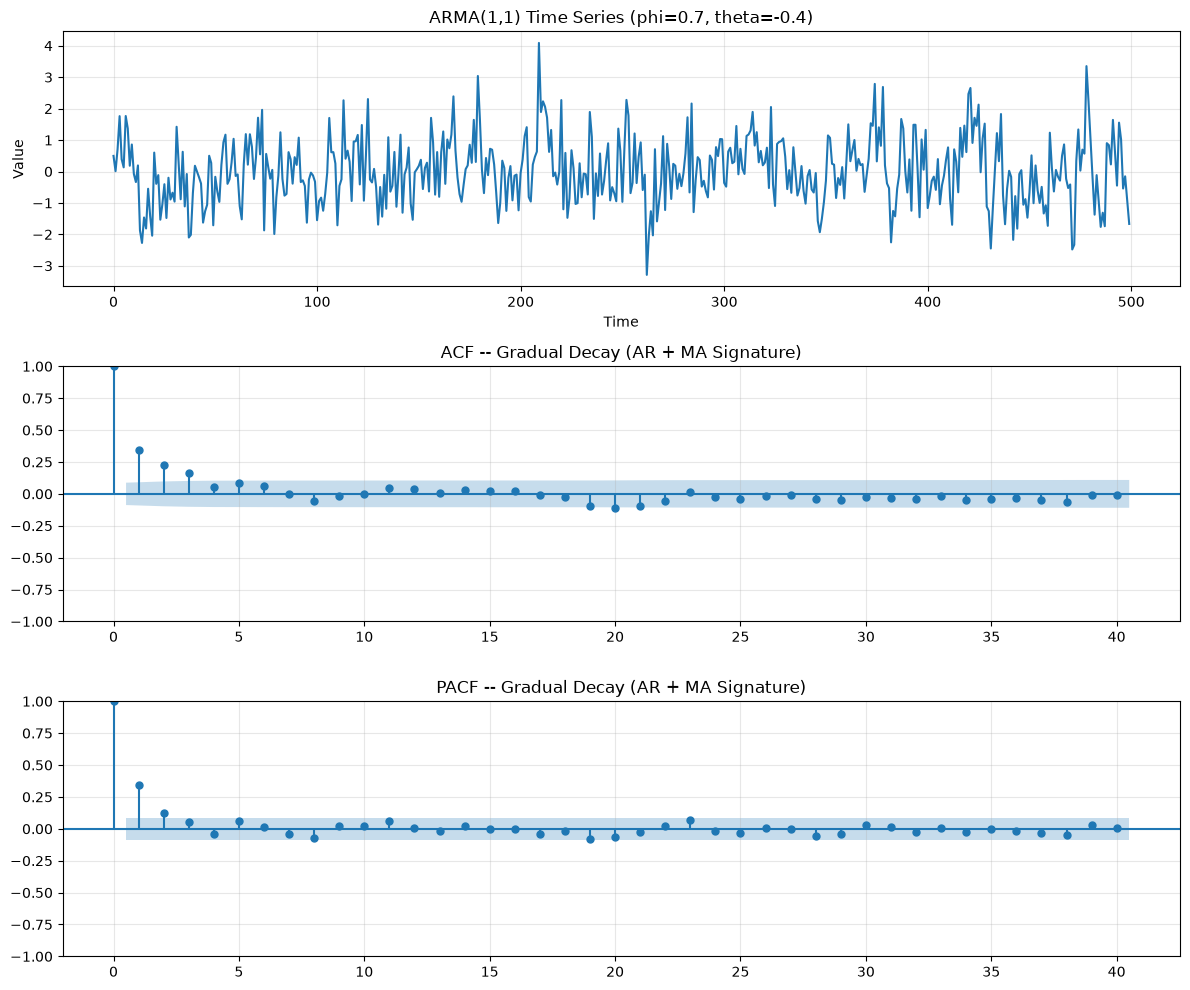

In [34]:
print("=" * 60)
print("SECTION 2: ACF and PACF Analysis")
print("=" * 60)

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

# Time series plot
axes[0].plot(arma_series)
axes[0].set_title('ARMA(1,1) Time Series (phi=0.7, theta=-0.4)')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Value')
axes[0].grid(True, alpha=0.3)

# ACF -- gradual decay (AR + MA signature)
plot_acf(arma_series, lags=40, ax=axes[1])
axes[1].set_title('ACF -- Gradual Decay (AR + MA Signature)')
axes[1].grid(True, alpha=0.3)

# PACF -- gradual decay (AR + MA signature)
plot_pacf(arma_series, lags=40, ax=axes[2])
axes[2].set_title('PACF -- Gradual Decay (AR + MA Signature)')
axes[2].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '01_arma_acf_pacf.png'), dpi=100)
print("  Saved ACF/PACF analysis plot\n")


## 3. Grid Search for Best (p, q) with AIC Heatmap


SECTION 3: Grid Search for Best (p, q) with AIC Heatmap
  Best ARMA by AIC: ARMA(5, 2)
  AIC: 1405.73, BIC: 1443.66



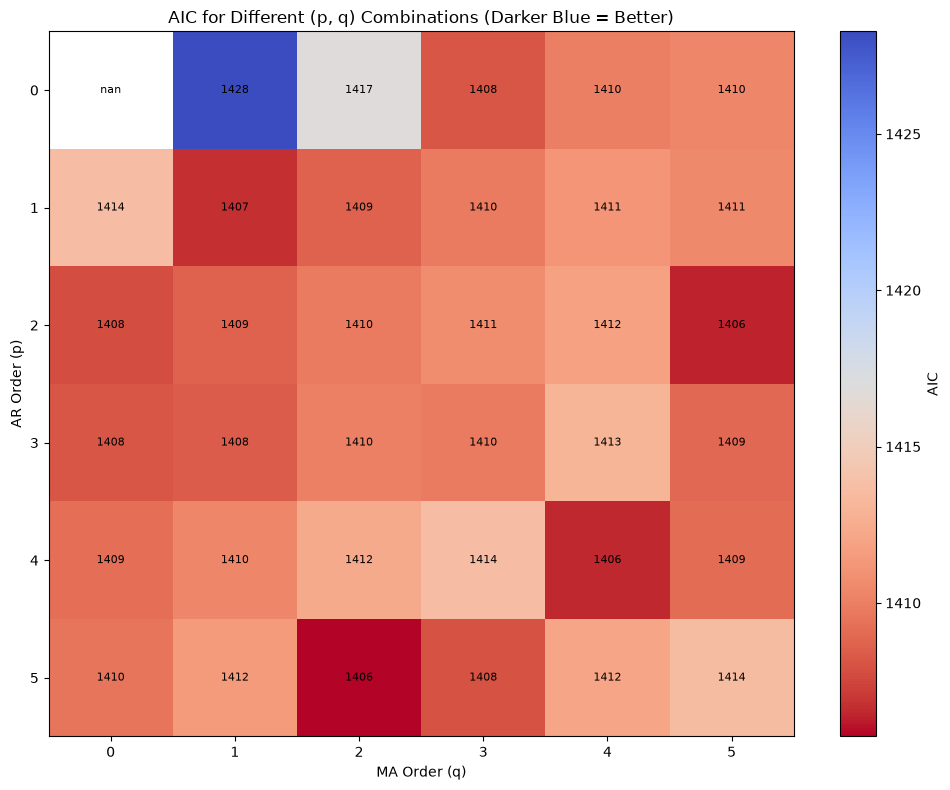

In [35]:
print("=" * 60)
print("SECTION 3: Grid Search for Best (p, q) with AIC Heatmap")
print("=" * 60)

def find_best_arma_order(series, max_p=5, max_q=5):
    """Grid search over (p, q) and return the best order by AIC."""
    results = []

    for p in range(max_p + 1):
        for q in range(max_q + 1):
            if p == 0 and q == 0:
                continue
            try:
                model = ARIMA(series, order=(p, 0, q))
                fitted = model.fit()
                results.append({
                    'p': p, 'q': q,
                    'AIC': fitted.aic,
                    'BIC': fitted.bic,
                    'MSE': np.mean(fitted.resid ** 2)
                })
            except Exception:
                continue

    results_df = pd.DataFrame(results)
    best_row = results_df.loc[results_df['AIC'].idxmin()]

    print(f"  Best ARMA by AIC: ARMA({int(best_row['p'])}, {int(best_row['q'])})")
    print(f"  AIC: {best_row['AIC']:.2f}, BIC: {best_row['BIC']:.2f}")

    # Heatmap
    pivot = results_df.pivot(index='p', columns='q', values='AIC')
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(pivot, cmap='coolwarm_r', aspect='auto')
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_yticks(range(len(pivot.index)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel('MA Order (q)')
    ax.set_ylabel('AR Order (p)')
    ax.set_title('AIC for Different (p, q) Combinations (Darker Blue = Better)')

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.iloc[i, j]
            ax.text(j, i, f'{val:.0f}', ha='center', va='center', fontsize=8)

    plt.colorbar(im, ax=ax, label='AIC')
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, '02_arma_aic_heatmap.png'), dpi=100)
    return (int(best_row['p']), int(best_row['q'])), results_df

best_order, grid_results = find_best_arma_order(arma_series, max_p=5, max_q=5)
print()


## 4. ARMA Fitting and Residual Diagnostics


SECTION 4: ARMA Fitting and Residual Diagnostics
  ARMA(5,2) -- AIC: 1309.63, BIC: 1347.00
    const: 0.0192
    ar.L1: 0.8401
    ar.L2: -0.7459
    ar.L3: 0.1805
    ar.L4: 0.0106
    ar.L5: 0.1296
    ma.L1: -0.5755
    ma.L2: 0.7269
    sigma2: 0.9136

  Ljung-Box p-values: {10: 0.9998258245937719, 20: 0.9997725499035405, 30: 0.995407132161785}
  Forecast RMSE: 1.3451
  Saved diagnostic plots



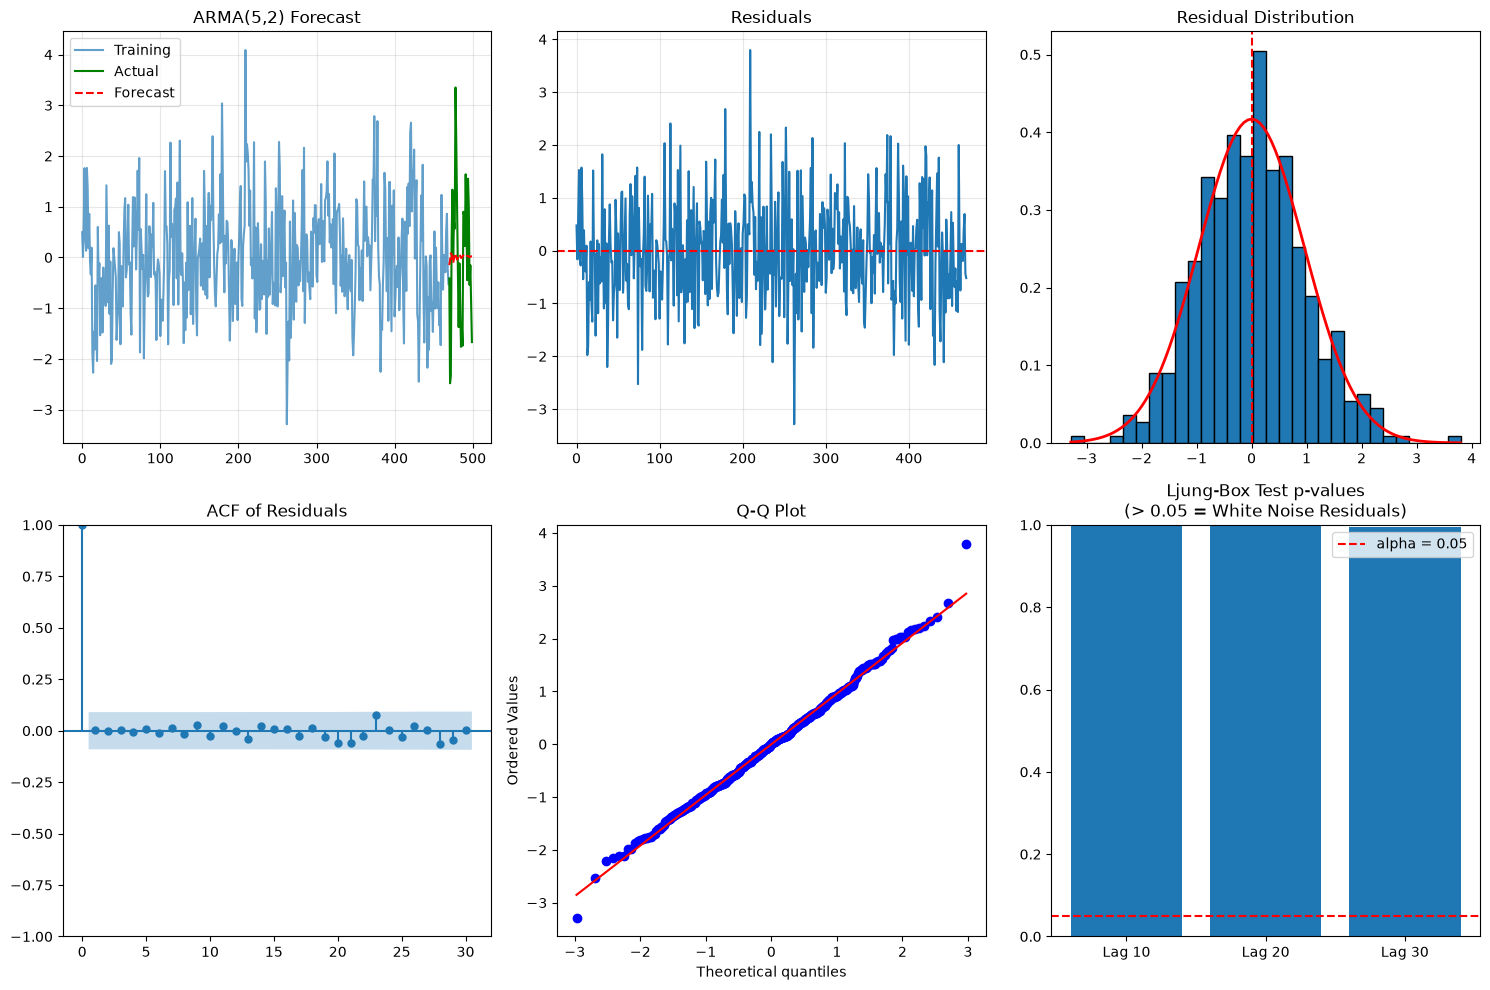

In [36]:
print("=" * 60)
print("SECTION 4: ARMA Fitting and Residual Diagnostics")
print("=" * 60)

def arma_diagnostics(series, order, test_size=30):
    """Fit ARMA(p,q), forecast, and run full residual diagnostics."""
    p, q = order
    train = series[:-test_size]
    test = series[-test_size:]

    model = ARIMA(train, order=(p, 0, q))
    fitted = model.fit()

    print(f"  ARMA({p},{q}) -- AIC: {fitted.aic:.2f}, BIC: {fitted.bic:.2f}")
    for name, val in fitted.params.items():
        print(f"    {name}: {val:.4f}")

    # Forecast
    forecast = fitted.forecast(steps=len(test))
    forecast = pd.Series(forecast, index=test.index)
    residuals = fitted.resid

    # Ljung-Box test
    lb = acorr_ljungbox(residuals.dropna(), lags=[10, 20, 30], return_df=True)
    print(f"\n  Ljung-Box p-values: {lb['lb_pvalue'].to_dict()}")

    # Performance
    mse = mean_squared_error(test, forecast)
    rmse = np.sqrt(mse)
    print(f"  Forecast RMSE: {rmse:.4f}")

    # ---- Diagnostic plots ----
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # 1. Series + forecast
    axes[0, 0].plot(train.index, train, label='Training', alpha=0.7)
    axes[0, 0].plot(test.index, test, label='Actual', color='green')
    axes[0, 0].plot(test.index, forecast, label='Forecast', color='red', linestyle='--')
    axes[0, 0].set_title(f'ARMA({p},{q}) Forecast')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # 2. Residuals
    axes[0, 1].plot(residuals)
    axes[0, 1].axhline(y=0, color='r', linestyle='--')
    axes[0, 1].set_title('Residuals')
    axes[0, 1].grid(True, alpha=0.3)

    # 3. Residual histogram
    axes[0, 2].hist(residuals.dropna(), bins=30, edgecolor='black', density=True)
    x_range = np.linspace(residuals.min(), residuals.max(), 100)
    axes[0, 2].plot(x_range, scipy_stats.norm.pdf(x_range, 0, residuals.std()),
                    'r-', linewidth=2)
    axes[0, 2].set_title('Residual Distribution')
    axes[0, 2].axvline(x=0, color='r', linestyle='--')

    # 4. ACF of residuals
    plot_acf(residuals.dropna(), lags=30, ax=axes[1, 0])
    axes[1, 0].set_title('ACF of Residuals')

    # 5. Q-Q plot
    scipy_stats.probplot(residuals.dropna(), dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title('Q-Q Plot')

    # 6. Ljung-Box p-values bar
    axes[1, 2].bar(['Lag 10', 'Lag 20', 'Lag 30'], lb['lb_pvalue'].values)
    axes[1, 2].axhline(y=0.05, color='r', linestyle='--', label='alpha = 0.05')
    axes[1, 2].set_title('Ljung-Box Test p-values\n(> 0.05 = White Noise Residuals)')
    axes[1, 2].set_ylim(0, 1)
    axes[1, 2].legend()

    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, '03_arma_diagnostics.png'), dpi=100)
    print("  Saved diagnostic plots\n")

    return fitted, forecast, residuals

fitted_arma, fc_arma, res_arma = arma_diagnostics(arma_series, best_order)


---
## Arima Models


In [37]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ---------- Setup ----------
OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)
n_obs = 300


## 0. Generate Non-Stationary Data (Random Walk with Drift)


SECTION 0: Generate Non-Stationary Data
  Generated non-stationary series (random walk with drift)



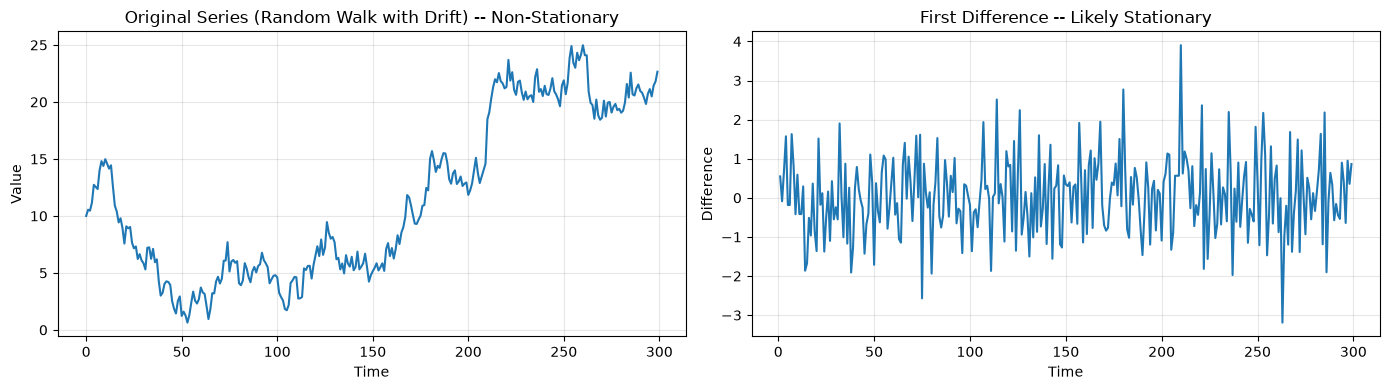

In [38]:
print("=" * 60)
print("SECTION 0: Generate Non-Stationary Data")
print("=" * 60)
np.random.seed(42)

y = [10]
for i in range(1, n_obs):
    y.append(y[-1] + 0.05 + np.random.normal(0, 1))

series = pd.Series(y, name='NonStationary')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(series)
axes[0].set_title('Original Series (Random Walk with Drift) -- Non-Stationary')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Value')
axes[0].grid(True, alpha=0.3)

# First difference
axes[1].plot(series.diff().dropna())
axes[1].set_title('First Difference -- Likely Stationary')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Difference')
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '01_nonstationary_data.png'), dpi=100)
print("  Generated non-stationary series (random walk with drift)\n")


## 1. Determine Optimal d with ADF Test


In [39]:
print("=" * 60)
print("SECTION 1: Determine Optimal d via ADF Test")
print("=" * 60)

def determine_d(series, max_d=2):
    """Find the minimum differencing order d that makes the series stationary."""
    print(f"{'d':<4} {'ADF Stat':<12} {'p-value':<12} {'Stationary?':<15}")
    print("-" * 45)

    for d in range(max_d + 1):
        if d == 0:
            test_series = series.dropna()
        else:
            test_series = series.diff(d).dropna()

        adf_stat, p_val, _, _, crit_values, _ = adfuller(test_series)
        is_stationary = "YES" if p_val < 0.05 else "NO"
        print(f"{d:<4} {adf_stat:<12.4f} {p_val:<12.6f} {is_stationary:<15}")

        if p_val < 0.05:
            print(f"\n  --> Optimal d = {d}")
            return d, test_series

    print(f"\n  --> Warning: Not stationary even at d={max_d}, using d={max_d}")
    return max_d, series.diff(max_d).dropna()

d_opt, diff_series = determine_d(series)
print()


SECTION 1: Determine Optimal d via ADF Test
d    ADF Stat     p-value      Stationary?    
---------------------------------------------
0    -0.5541      0.881011     NO             
1    -18.6289     0.000000     YES            

  --> Optimal d = 1



## 2. Identify p, q with ACF / PACF


SECTION 2: Identify p and q via ACF / PACF
  Estimated p (from PACF): 0
  Estimated q (from ACF):  0



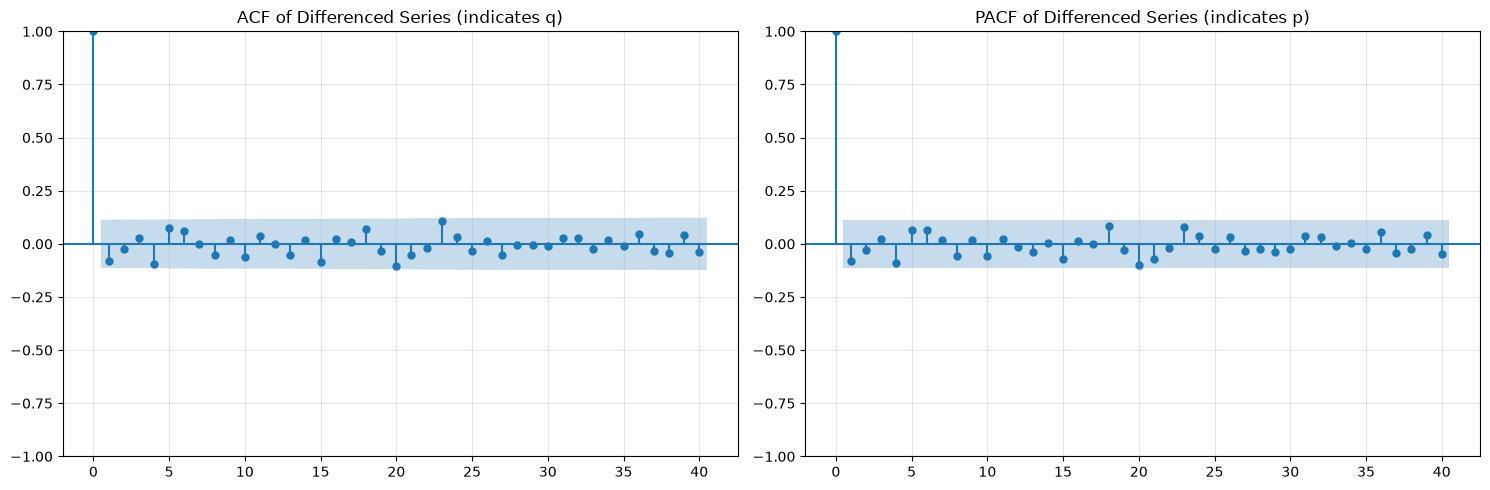

In [40]:
print("=" * 60)
print("SECTION 2: Identify p and q via ACF / PACF")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(diff_series.dropna(), lags=40, ax=axes[0])
axes[0].set_title('ACF of Differenced Series (indicates q)')
axes[0].grid(True, alpha=0.3)

plot_pacf(diff_series.dropna(), lags=40, ax=axes[1])
axes[1].set_title('PACF of Differenced Series (indicates p)')
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '02_arima_acf_pacf.png'), dpi=100)
# Automatic estimation
acf_vals, acf_ci = acf(diff_series.dropna(), nlags=40, alpha=0.05)
pacf_vals, pacf_ci = pacf(diff_series.dropna(), nlags=40, alpha=0.05)

acf_sig = np.where(np.abs(acf_vals[1:]) > (acf_ci[1:, 1] - acf_vals[1:]))[0]
q_est = acf_sig[-1] + 1 if len(acf_sig) > 0 else 0

pacf_sig = np.where(np.abs(pacf_vals[1:]) > (pacf_ci[1:, 1] - pacf_vals[1:]))[0]
p_est = pacf_sig[-1] + 1 if len(pacf_sig) > 0 else 0

print(f"  Estimated p (from PACF): {p_est}")
print(f"  Estimated q (from ACF):  {q_est}\n")


## 3. Grid Search for Best ARIMA with AIC (Box-Jenkins Step 2)


In [41]:
print("=" * 60)
print("SECTION 3: Grid Search for Best ARIMA(p,d,q) via AIC")
print("=" * 60)

def grid_search_arima(series, d, max_p=5, max_q=5):
    """Grid search over p and q with fixed d, ranking by AIC."""
    results = []

    for p in range(max_p + 1):
        for q in range(max_q + 1):
            if p == 0 and q == 0:
                continue
            try:
                model = ARIMA(series, order=(p, d, q))
                fitted = model.fit()
                results.append({
                    'model': f'ARIMA({p},{d},{q})',
                    'p': p, 'd': d, 'q': q,
                    'AIC': fitted.aic,
                    'BIC': fitted.bic,
                })
            except Exception:
                continue

    results_df = pd.DataFrame(results).sort_values('AIC').reset_index(drop=True)
    print("\nTop 5 Models:")
    print(results_df.head(5).to_string(index=False))

    best = results_df.iloc[0]
    print(f"\n  Best model: {best['model']} with AIC = {best['AIC']:.2f}")
    return best, results_df

best_row, all_results = grid_search_arima(series, d=d_opt, max_p=5, max_q=5)
p_opt, d_opt, q_opt = int(best_row['p']), int(best_row['d']), int(best_row['q'])
print()


SECTION 3: Grid Search for Best ARIMA(p,d,q) via AIC

Top 5 Models:
       model  p  d  q        AIC        BIC
ARIMA(0,1,1)  0  1  1 841.213714 848.614601
ARIMA(1,1,0)  1  1  0 841.302422 848.703309
ARIMA(3,1,5)  3  1  5 843.034790 876.338783
ARIMA(2,1,0)  2  1  0 843.070971 854.172302
ARIMA(0,1,2)  0  1  2 843.091695 854.193026

  Best model: ARIMA(0,1,1) with AIC = 841.21



## 4. Box-Jenkins: Train & Full Residual Diagnostics


SECTION 4: Box-Jenkins -- Fit, Diagnose, Forecast
  ARIMA(0,1,1) -- AIC: 667.37, BIC: 674.32
  Forecast: MSE=3.0090, RMSE=1.7346, MAE=1.2904
  Ljung-Box p-values: {10: 0.9728077632859543, 20: 0.9220613832608395, 30: 0.9720089069167266}
  Saved diagnostic plots



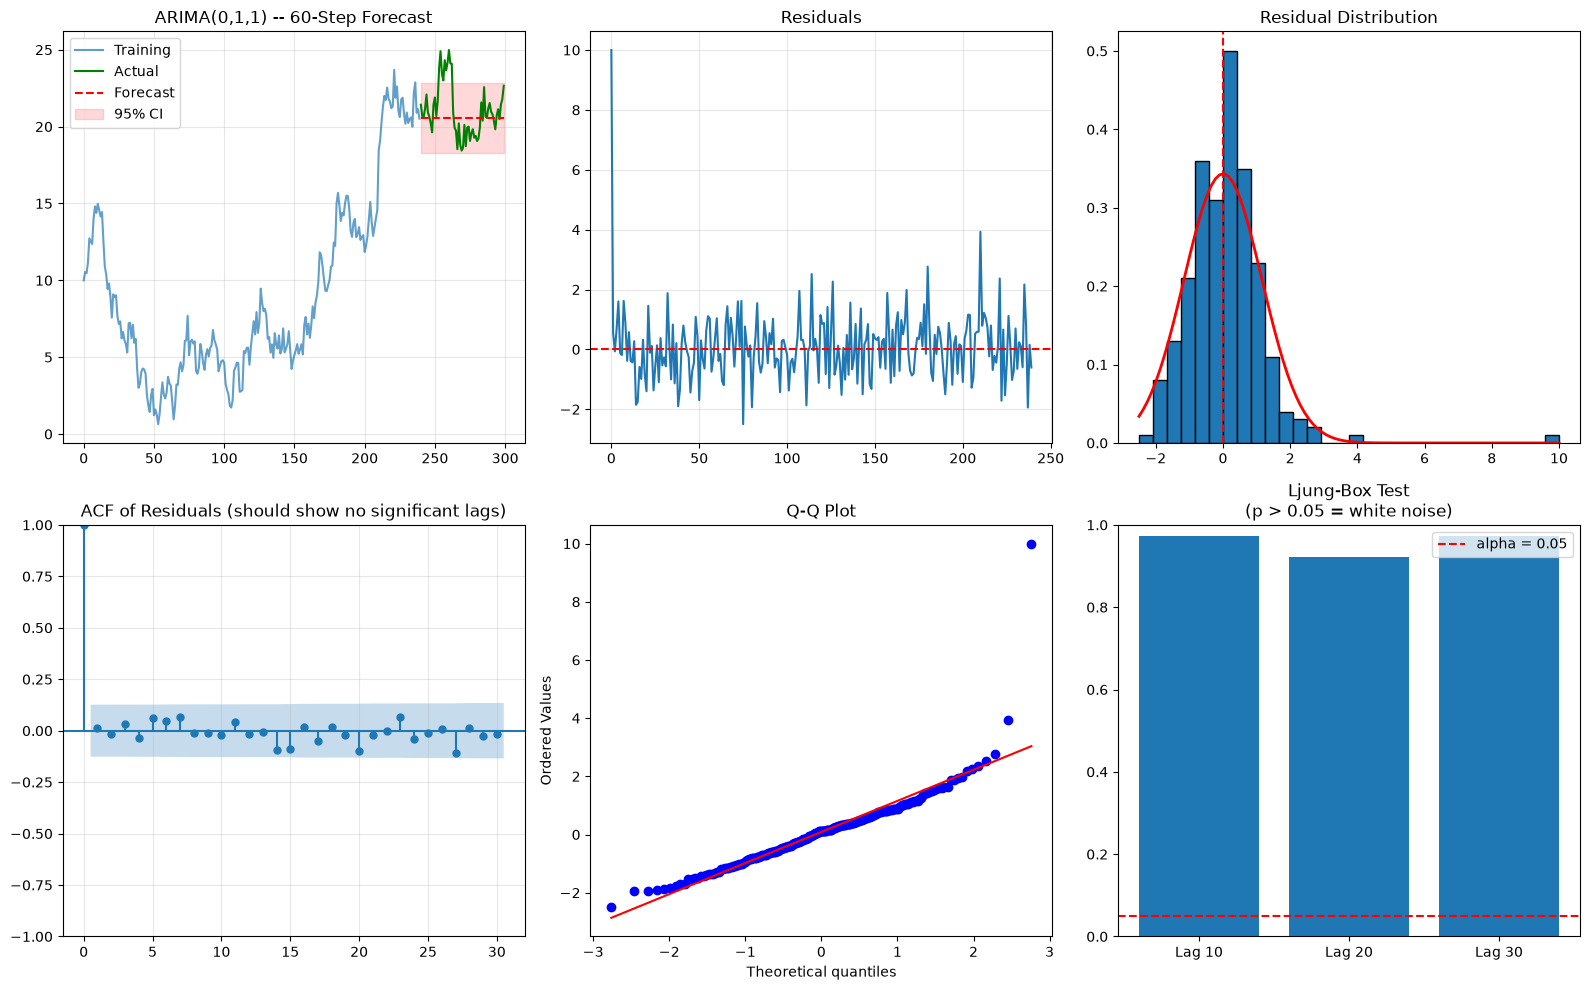

In [42]:
print("=" * 60)
print("SECTION 4: Box-Jenkins -- Fit, Diagnose, Forecast")
print("=" * 60)

def train_and_diagnose_arima(series, order):
    """Fit ARIMA, run residual diagnostics, and forecast."""
    p, d, q = order
    train_size = int(len(series) * 0.8)
    train = series[:train_size]
    test = series[train_size:]

    model = ARIMA(train, order=order)
    fitted = model.fit()

    print(f"  ARIMA({p},{d},{q}) -- AIC: {fitted.aic:.2f}, BIC: {fitted.bic:.2f}")

    forecast = fitted.forecast(steps=len(test))
    forecast = pd.Series(forecast, index=test.index)
    residuals = fitted.resid

    # ---- Performance ----
    mse = mean_squared_error(test, forecast)
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mse)
    print(f"  Forecast: MSE={mse:.4f}, RMSE={rmse:.4f}, MAE={mae:.4f}")

    # ---- Residual diagnostics ----
    lb = acorr_ljungbox(residuals.dropna(), lags=[10, 20, 30], return_df=True)
    print(f"  Ljung-Box p-values: {lb['lb_pvalue'].to_dict()}")

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))

    # 1. Training + test + forecast
    axes[0, 0].plot(train.index, train, label='Training', alpha=0.7)
    axes[0, 0].plot(test.index, test, label='Actual', color='green')
    axes[0, 0].plot(test.index, forecast, label='Forecast', color='red', linestyle='--')
    axes[0, 0].fill_between(test.index,
                             forecast - 1.96 * residuals.std(),
                             forecast + 1.96 * residuals.std(),
                             alpha=0.15, color='red', label='95% CI')
    axes[0, 0].set_title(f'ARIMA({p},{d},{q}) -- {len(test)}-Step Forecast')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # 2. Residuals
    axes[0, 1].plot(residuals)
    axes[0, 1].axhline(y=0, color='r', linestyle='--')
    axes[0, 1].set_title('Residuals')
    axes[0, 1].grid(True, alpha=0.3)

    # 3. Residual histogram + normal PDF
    axes[0, 2].hist(residuals.dropna(), bins=30, edgecolor='black', density=True)
    xr = np.linspace(residuals.min(), residuals.max(), 100)
    axes[0, 2].plot(xr, stats.norm.pdf(xr, 0, residuals.std()), 'r-', linewidth=2)
    axes[0, 2].set_title('Residual Distribution')
    axes[0, 2].axvline(x=0, color='r', linestyle='--')

    # 4. ACF of residuals
    plot_acf(residuals.dropna(), lags=30, ax=axes[1, 0])
    axes[1, 0].set_title('ACF of Residuals (should show no significant lags)')
    axes[1, 0].grid(True, alpha=0.3)

    # 5. Q-Q plot
    stats.probplot(residuals.dropna(), dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title('Q-Q Plot')

    # 6. Ljung-Box bar chart
    axes[1, 2].bar(['Lag 10', 'Lag 20', 'Lag 30'], lb['lb_pvalue'].values)
    axes[1, 2].axhline(y=0.05, color='r', linestyle='--', label='alpha = 0.05')
    axes[1, 2].set_title('Ljung-Box Test\n(p > 0.05 = white noise)')
    axes[1, 2].set_ylim(0, 1)
    axes[1, 2].legend()

    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, '03_arima_diagnostics.png'), dpi=100)
    print("  Saved diagnostic plots\n")

    return fitted, forecast, test, residuals

fitted_model, forecast_vals, actuals, resids = train_and_diagnose_arima(
    series, order=(p_opt, d_opt, q_opt)
)


---
## Sarima Models


In [43]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error

# ---------- Setup ----------
OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)
n_obs = 300
seasonal_period = 12


## 0. Create Seasonal Data (Trend + Yearly Seasonality + Noise)


SECTION 0: Creating Synthetic Seasonal Data
  Created seasonal data with period = 12



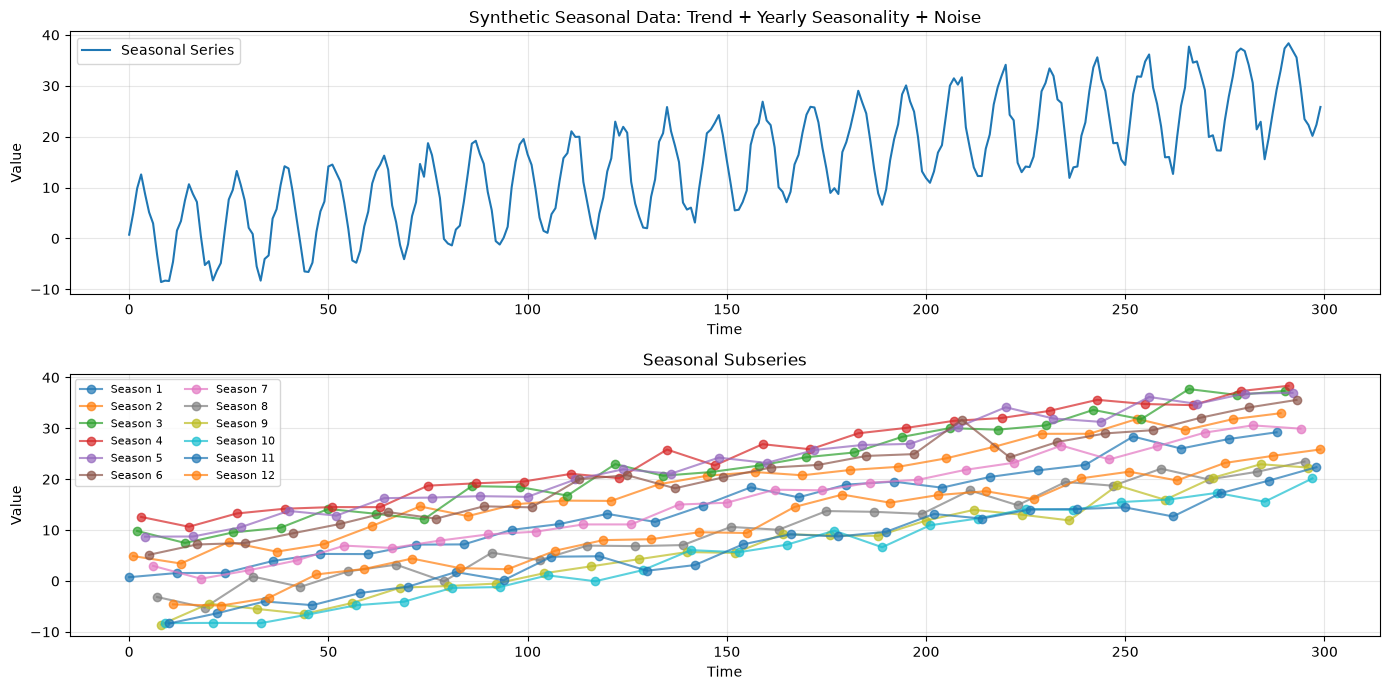

In [44]:
print("=" * 60)
print("SECTION 0: Creating Synthetic Seasonal Data")
print("=" * 60)
np.random.seed(42)

t = np.arange(n_obs)
trend = 0.1 * t
seasonal = 10 * np.sin(2 * np.pi * t / seasonal_period)
noise = np.random.normal(0, 1.5, n_obs)
data = trend + seasonal + noise

series = pd.Series(data, name='SeasonalData')

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(series, label='Seasonal Series')
axes[0].set_title('Synthetic Seasonal Data: Trend + Yearly Seasonality + Noise')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Value')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Seasonal subseries plot (one line per season)
seasonal_view = pd.DataFrame({'value': series, 'month': np.mod(t, seasonal_period)})
for m in range(seasonal_period):
    mask = seasonal_view['month'] == m
    axes[1].plot(seasonal_view.loc[mask].index,
                 seasonal_view.loc[mask, 'value'],
                 'o-', label=f'Season {m+1}', alpha=0.7)
axes[1].set_title('Seasonal Subseries')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Value')
axes[1].legend(loc='upper left', ncol=2, fontsize=8)
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '01_seasonal_data.png'), dpi=100)
print("  Created seasonal data with period = 12\n")


## 1. Seasonal Differencing to Find D


In [45]:
print("=" * 60)
print("SECTION 1: Seasonal Differencing to Determine D")
print("=" * 60)

def determine_seasonal_d(series, s):
    """Test seasonal differencing via ADF on series.diff(s)."""
    print(f"  Testing seasonal difference (s={s}):")
    seasonal_diff = series.diff(s).dropna()
    p_value = adfuller(seasonal_diff)[1]
    print(f"    ADF p-value on diff({s}): {p_value:.6f}")

    if p_value < 0.05:
        print(f"    --> D = 1 is sufficient")
        return 1
    else:
        print(f"    --> D = 1 may not be enough; using D = 1 anyway")
        return 1

D_opt = determine_seasonal_d(series, seasonal_period)
print()


SECTION 1: Seasonal Differencing to Determine D
  Testing seasonal difference (s=12):
    ADF p-value on diff(12): 0.000000
    --> D = 1 is sufficient



## 2. Seasonal ACF / PACF for P, Q


SECTION 2: Seasonal ACF / PACF Analysis for P and Q
  Saved seasonal ACF/PACF plot



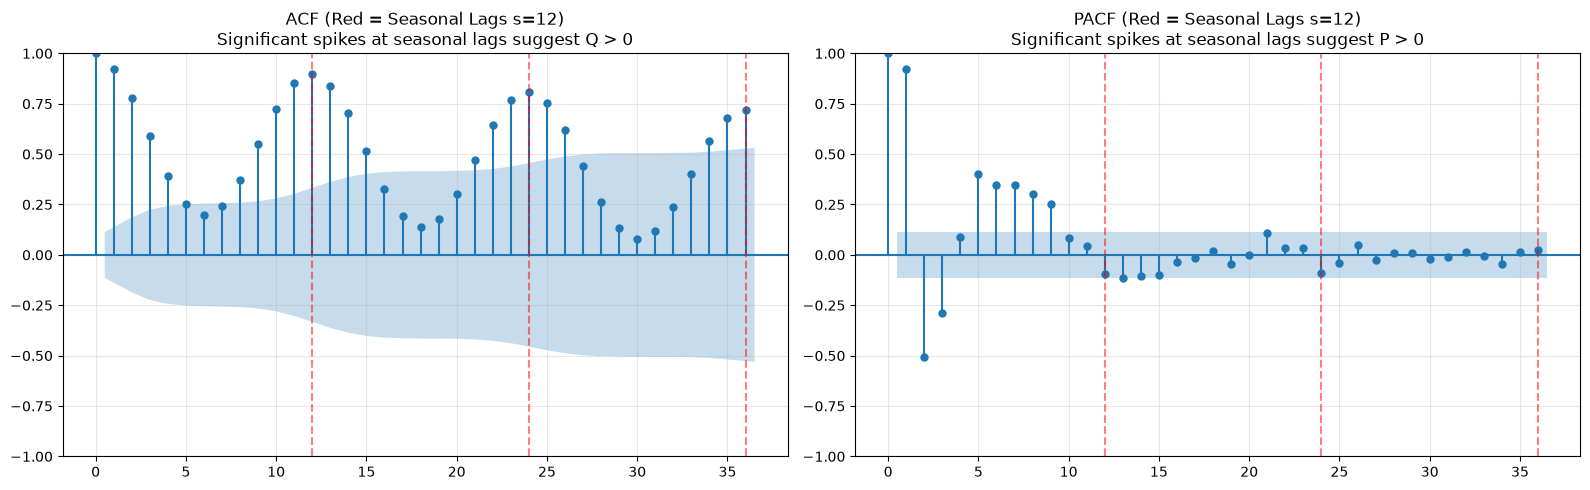

In [46]:
print("=" * 60)
print("SECTION 2: Seasonal ACF / PACF Analysis for P and Q")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(series.dropna(), lags=3 * seasonal_period, ax=axes[0])
for i in range(1, 4):
    axes[0].axvline(x=i * seasonal_period, color='red', linestyle='--', alpha=0.5)
axes[0].set_title(f'ACF (Red = Seasonal Lags s={seasonal_period})\nSignificant '
                  f'spikes at seasonal lags suggest Q > 0')
axes[0].grid(True, alpha=0.3)

plot_pacf(series.dropna(), lags=3 * seasonal_period, ax=axes[1])
for i in range(1, 4):
    axes[1].axvline(x=i * seasonal_period, color='red', linestyle='--', alpha=0.5)
axes[1].set_title(f'PACF (Red = Seasonal Lags s={seasonal_period})\nSignificant '
                  f'spikes at seasonal lags suggest P > 0')
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '02_seasonal_acf_pacf.png'), dpi=100)
print("  Saved seasonal ACF/PACF plot\n")


## 3. Fit SARIMA with statsmodels SARIMAX


SECTION 3: Fitting SARIMA with SARIMAX
  SARIMA(1, 1, 1)x(1, 1, 1, 12)
  AIC: 799.79, BIC: 816.59
  Coefficients:
    ar.L1: -0.1144
    ma.L1: -1.0000
    ar.S.L12: -0.1314
    ma.S.L12: -1.0000
    sigma2: 1.9623

  Test RMSE: 1.6448
  Saved SARIMA forecast plot



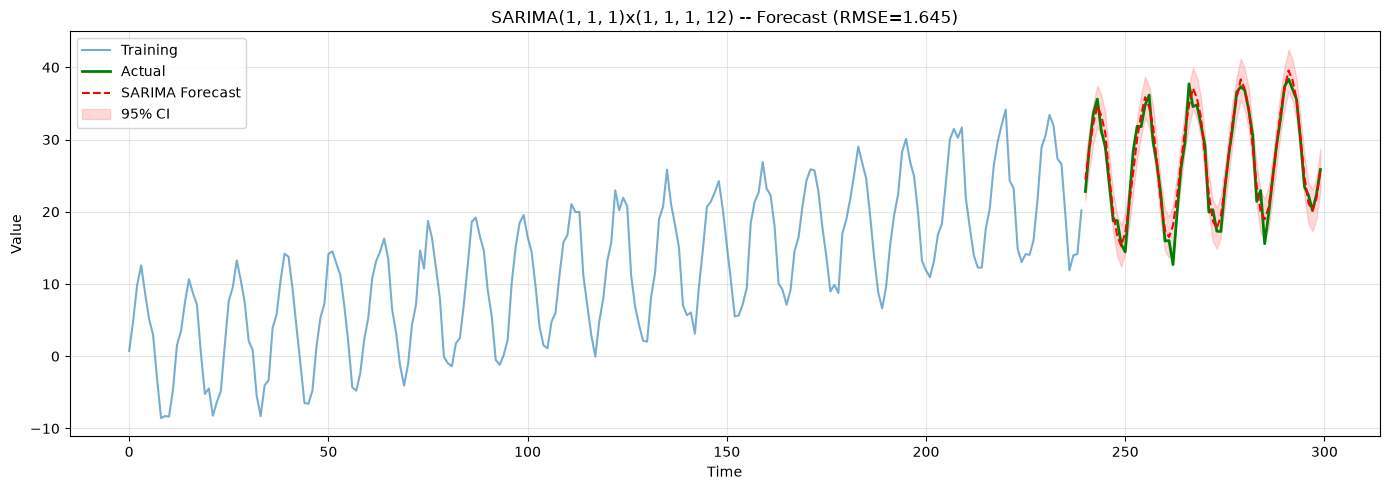

In [47]:
print("=" * 60)
print("SECTION 3: Fitting SARIMA with SARIMAX")
print("=" * 60)

# Split data
train_size = int(len(series) * 0.8)
train = series[:train_size]
test = series[train_size:]

# SARIMA(1,1,1)(1,1,1,12)
sarima_order = (1, 1, 1)
seasonal_order = (1, 1, 1, seasonal_period)

model = SARIMAX(train,
                order=sarima_order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False)
fitted = model.fit(disp=False)

print(f"  SARIMA{sarima_order}x{seasonal_order}")
print(f"  AIC: {fitted.aic:.2f}, BIC: {fitted.bic:.2f}")
print(f"  Coefficients:")
for name, val in fitted.params.items():
    print(f"    {name}: {val:.4f}")

# Forecast
forecast_result = fitted.get_forecast(steps=len(test))
forecast = forecast_result.predicted_mean
conf_int = forecast_result.conf_int(alpha=0.05)

# Performance
mse = mean_squared_error(test, forecast)
rmse = np.sqrt(mse)
print(f"\n  Test RMSE: {rmse:.4f}")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train, label='Training', alpha=0.6)
ax.plot(test.index, test, label='Actual', color='green', linewidth=2)
ax.plot(test.index, forecast, label='SARIMA Forecast', color='red', linestyle='--')
ax.fill_between(test.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                alpha=0.15, color='red', label='95% CI')
ax.set_title(f'SARIMA{sarima_order}x{seasonal_order} -- Forecast (RMSE={rmse:.3f})')
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '03_sarima_forecast.png'), dpi=100)
print("  Saved SARIMA forecast plot\n")


## 4. Compare ARIMA vs SARIMA on Seasonal Data


SECTION 5: ARIMA vs SARIMA Comparison
  ARIMA(2,1,2) RMSE:  3.598
  SARIMA(1,1,1)(1,1,1,12) RMSE: 1.645
  Improvement: 54.3%
  Saved comparison plot



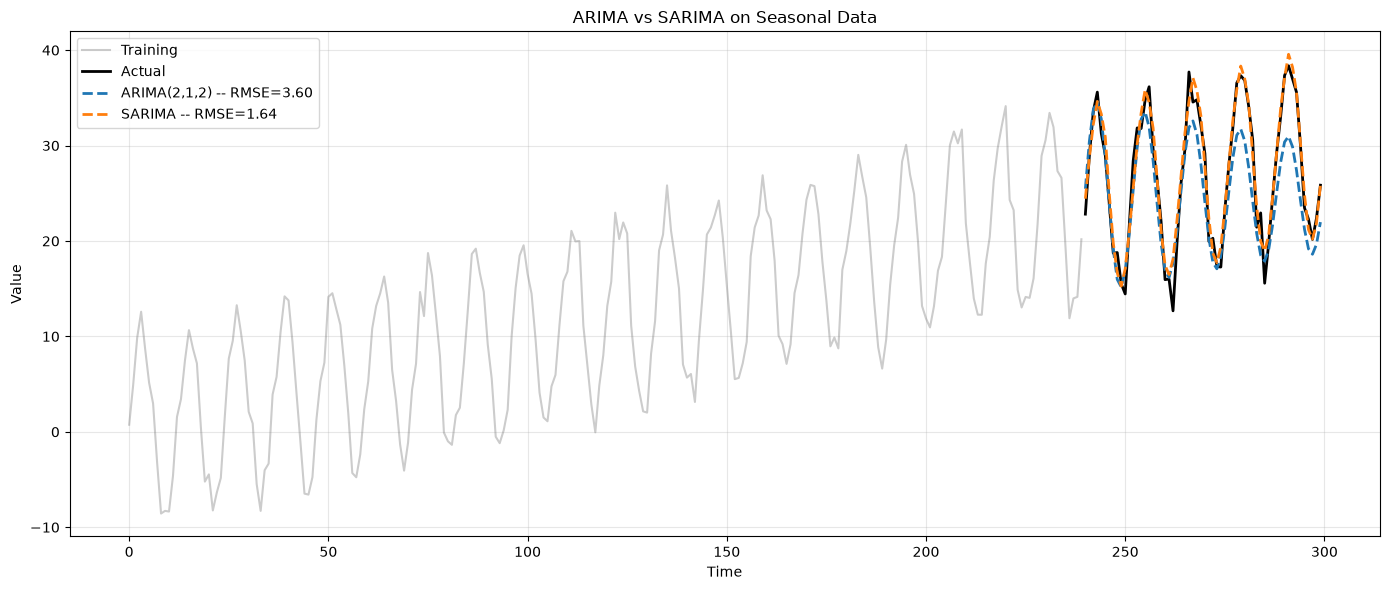

In [48]:
print("=" * 60)
print("SECTION 5: ARIMA vs SARIMA Comparison")
print("=" * 60)

# ARIMA (no seasonal component)
arima_model = ARIMA(train, order=(2, 1, 2))
arima_fitted = arima_model.fit()
arima_fc = arima_fitted.forecast(steps=len(test))
arima_rmse = np.sqrt(mean_squared_error(test, arima_fc))

# SARIMA (with seasonal component)
sarima_model = SARIMAX(train,
                       order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, seasonal_period),
                       enforce_stationarity=False,
                       enforce_invertibility=False)
sarima_fitted = sarima_model.fit(disp=False)
sarima_fc = sarima_fitted.forecast(steps=len(test))
sarima_rmse = np.sqrt(mean_squared_error(test, sarima_fc))

improvement = (1 - sarima_rmse / arima_rmse) * 100

print(f"  ARIMA(2,1,2) RMSE:  {arima_rmse:.3f}")
print(f"  SARIMA(1,1,1)(1,1,1,12) RMSE: {sarima_rmse:.3f}")
print(f"  Improvement: {improvement:.1f}%")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(train.index, train, label='Training', alpha=0.4, color='gray')
ax.plot(test.index, test, label='Actual', color='black', linewidth=2)
ax.plot(test.index, arima_fc,
        label=f'ARIMA(2,1,2) -- RMSE={arima_rmse:.2f}',
        linestyle='--', linewidth=2)
ax.plot(test.index, sarima_fc,
        label=f'SARIMA -- RMSE={sarima_rmse:.2f}',
        linestyle='--', linewidth=2)
ax.set_title('ARIMA vs SARIMA on Seasonal Data')
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, '05_arima_vs_sarima.png'), dpi=100)
print("  Saved comparison plot\n")


---
## Part-3 Complete!

All lessons finished successfully.
